# Chuard — calidad, limpieza y EDA de entrenamiento

El CSV original permanece inmutable. La inspección estructural describe el archivo
completo; las conclusiones y gráficos de desarrollo utilizan **solo entrenamiento**.
No se entrena ningún modelo ni se calculan métricas predictivas en este notebook.

La entrega incluye el manifiesto definitivo cuya huella coincide con el ganador.
La ruta alternativa de propuesta solo sirve para desarrollo cuando ese manifiesto
todavía no existe; no sustituye una asignación congelada ni acredita su aprobación.
La fuente del dataset, descarga, huella y guía de ejecución están en el README.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
if not (root / "src").is_dir() and (root.parent / "src").is_dir():
    root = root.parent
if not (root / "src").is_dir():
    raise RuntimeError("Abra el notebook desde la raíz de Chuard o notebooks/.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

In [2]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

from src.config import DATA_REPORT_DIR, RANDOM_STATE, RAW_DATA_PATH, SPLIT_MANIFEST_PATH
from src.data import (
    audit_dataset,
    dataset_sha256,
    generate_eda_report,
    read_customer_csv,
    summarize_training,
    training_subset_from_manifest,
)
from src.features import build_features
from src.schema import DERIVED_COLUMNS
from src.train import split_positions

if not RAW_DATA_PATH.is_file():
    raise FileNotFoundError("Obtenga el CSV original con python -m src.data download.")
original_hash = dataset_sha256(RAW_DATA_PATH)
quality = audit_dataset(RAW_DATA_PATH)
display(
    pd.Series(
        {
            "registros": quality["rows"],
            "columnas": quality["column_count"],
            "filas_duplicadas": quality["duplicate_rows"],
            "IDs_duplicados": quality["duplicate_customer_ids"],
            "TotalCharges_vacíos": quality["empty_values"]["TotalCharges"],
            "normalizaciones_a_cero": quality["total_charges_zero_normalizations"],
        }
    )
)
display(pd.Series(quality["target_counts"], name="Distribución estructural de Churn"))
print("SHA-256:", original_hash)
print("Antigüedad de los TotalCharges vacíos:", quality["total_charges_empty_tenure"])
print("No se eliminan clientes distintos que compartan perfil.")

registros                 7043
columnas                    21
filas_duplicadas             0
IDs_duplicados               0
TotalCharges_vacíos         11
normalizaciones_a_cero      11
dtype: int64

No     5174
Yes    1869
Name: Distribución estructural de Churn, dtype: int64

SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Antigüedad de los TotalCharges vacíos: {'0': 11}
No se eliminan clientes distintos que compartan perfil.


In [3]:
DATA_REPORT_DIR.mkdir(parents=True, exist_ok=True)
manifest_path = SPLIT_MANIFEST_PATH
if not manifest_path.is_file():
    manifest_path = DATA_REPORT_DIR / "splits_propuesta.json"
    if not manifest_path.is_file():
        normalized = read_customer_csv(RAW_DATA_PATH, mode="training").data
        labels = normalized["Churn"].map({"No": 0, "Yes": 1})
        proposal = {
            "dataset_sha256": original_hash,
            "random_state": RANDOM_STATE,
            "index_kind": "posición normalizada desde 0",
            "status": "propuesta_pendiente_confirmación_frente2",
            "splits": split_positions(labels),
        }
        manifest_path.write_text(json.dumps(proposal, indent=2), encoding="utf-8")
training = training_subset_from_manifest(RAW_DATA_PATH, manifest_path)
print("Manifiesto:", manifest_path.relative_to(root))
print("Estado:", training.attrs["split_status"])
print("Registros de entrenamiento:", len(training))
print("No se calculan conclusiones sobre validación/prueba.")

Manifiesto:

 reports\modeling\splits.json
Estado: estado_no_documentado
Registros de entrenamiento: 4225
No se calculan conclusiones sobre validación/prueba.


In [4]:
before = training.copy(deep=True)
with_features = build_features(training)
pd.testing.assert_frame_equal(training, before)
assert "customerID" not in with_features and "Churn" not in with_features
display(with_features.loc[:, list(DERIVED_COLUMNS)].describe())
summary = summarize_training(training)
display(pd.DataFrame(summary["numeric"]).T)
print("Los límites IQR son diagnósticos: no eliminan ni truncan valores.")
print("Cargos altos propuestos (Q3 de entrenamiento):", summary["high_monthly_charges"])

,numero_servicios,cliente_nuevo,contrato_mensual,pago_automatico,sin_soporte_tecnico,cargo_por_servicio
count,4225.000000,4225.000000,4225.000000,4225.000000,4225.000000,4225.000000
mean,4.174911,0.209467,0.545325,0.437396,0.482840,17.217013
std,2.339130,0.406977,0.498000,0.496124,0.499765,5.360819
min,1.000000,0.000000,0.000000,0.000000,0.000000,8.650000
25%,2.000000,0.000000,0.000000,0.000000,0.000000,12.875000
50%,4.000000,0.000000,1.000000,0.000000,0.000000,16.625000
75%,6.000000,0.000000,1.000000,1.000000,1.000000,20.075000
max,9.000000,1.000000,1.000000,1.000000,1.000000,35.900000


,observed,missing,min,max,median,mean,q1,q3,iqr_applicable,iqr_lower,iqr_upper,outside_iqr
SeniorCitizen,4225,0,0.0,1.0,0.0,0.16142,0.0,0.0,False,None,None,None
tenure,4225,0,0.0,72.0,29.0,32.44284,9.0,55.0,True,-60.0,124.0,0
MonthlyCharges,4225,0,18.4,118.75,70.55,64.894509,35.4,90.1,True,-46.65,172.15,0
TotalCharges,4225,0,0.0,8684.8,1372.45,2295.489408,399.6,3862.55,True,-4794.825,9056.975,0


Los límites IQR son diagnósticos: no eliminan ni truncan valores.
Cargos altos propuestos (Q3 de entrenamiento): 90.1


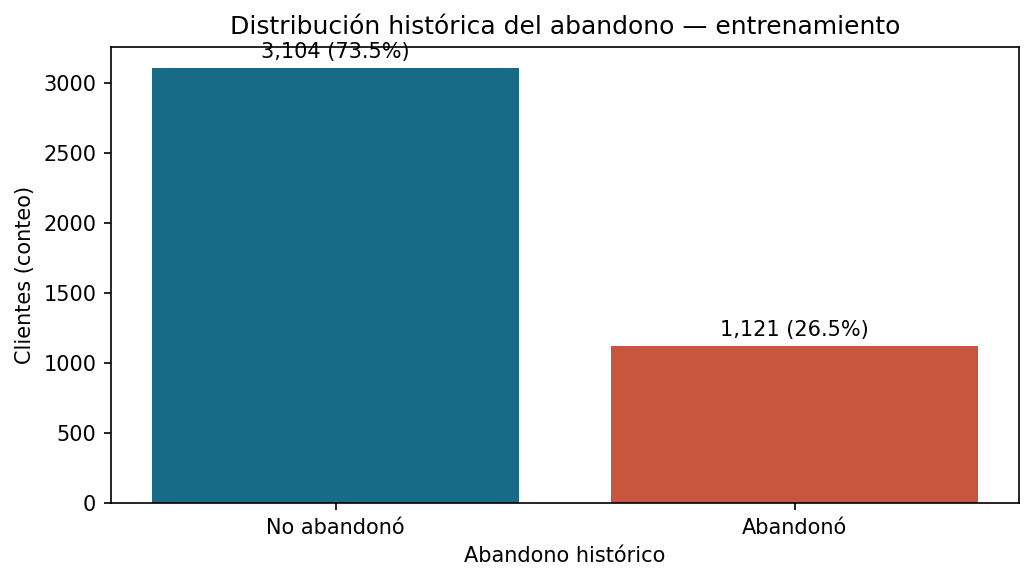

Abandonaron 1121 de 4225 clientes (26.5%); hay desbalance de clases.

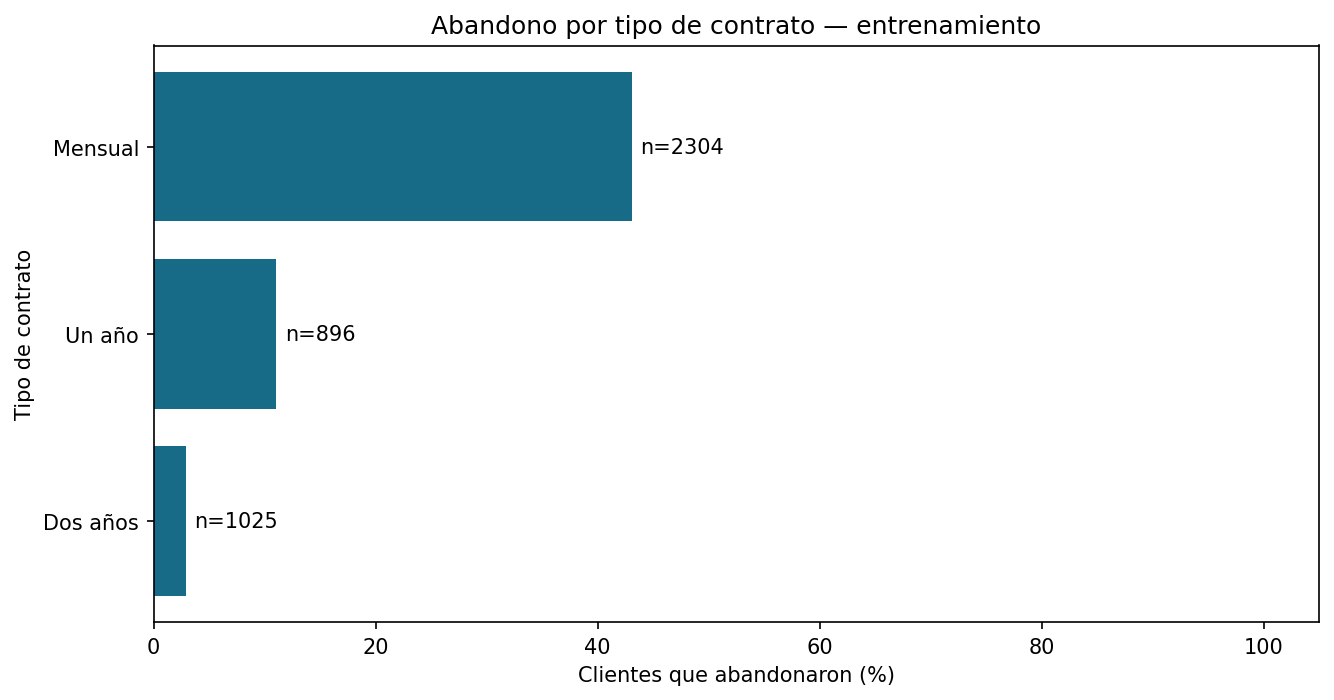

Month-to-month: 43.1% (n=2304); Two year: 2.9% (n=1025). Es una asociación histórica, no una causa demostrada.

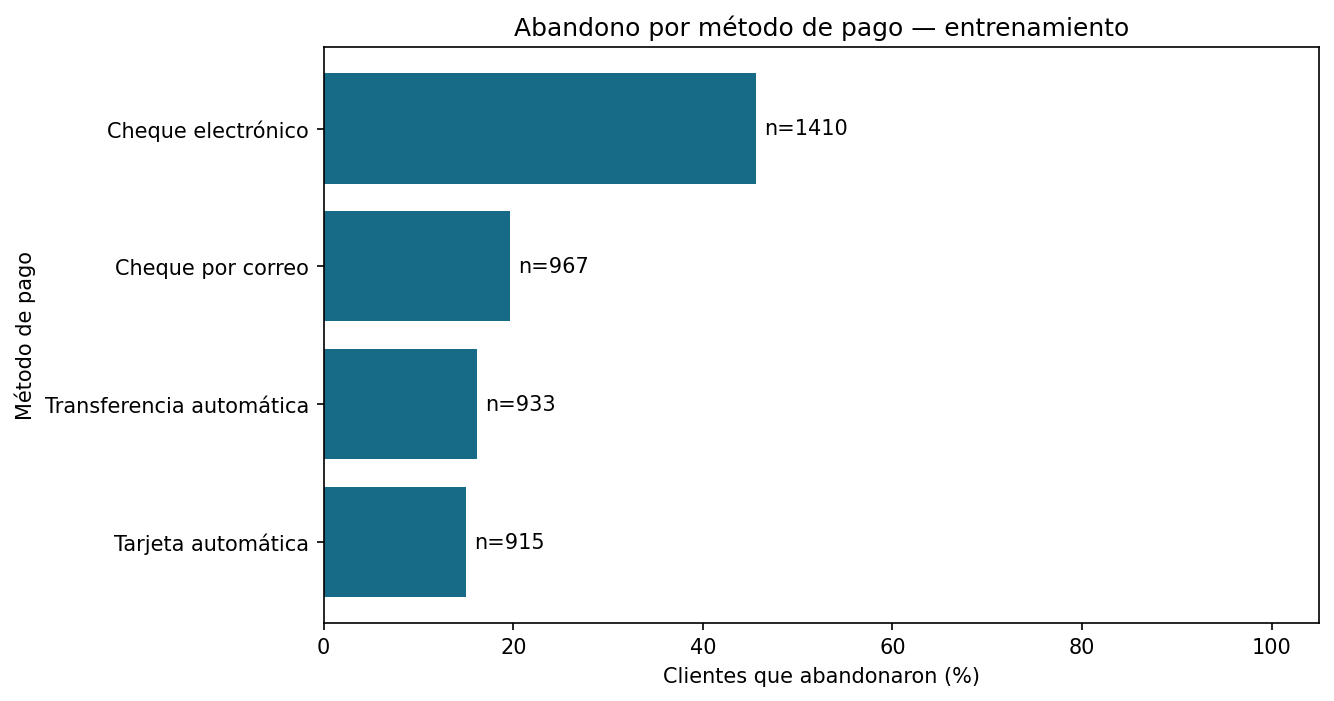

Electronic check: 45.6% (n=1410); Credit card (automatic): 15.0% (n=915). Es una asociación histórica, no una causa demostrada.

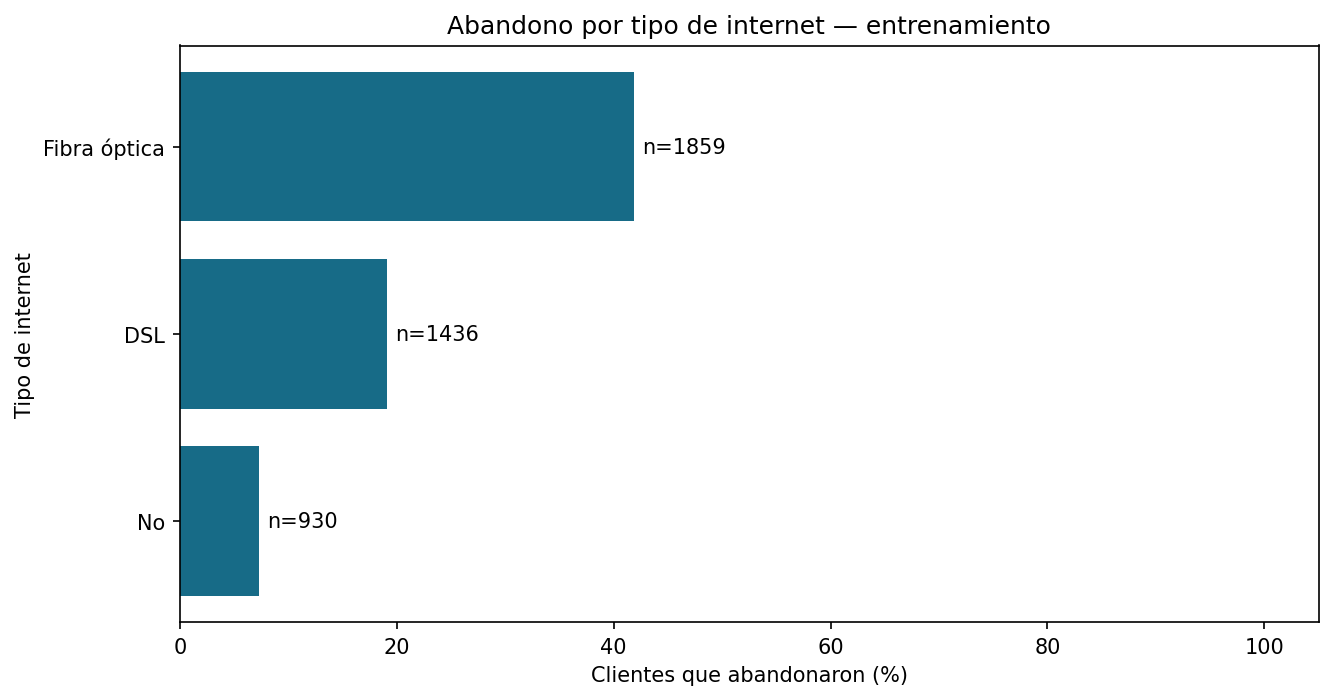

Fiber optic: 41.9% (n=1859); No: 7.3% (n=930). Es una asociación histórica, no una causa demostrada.

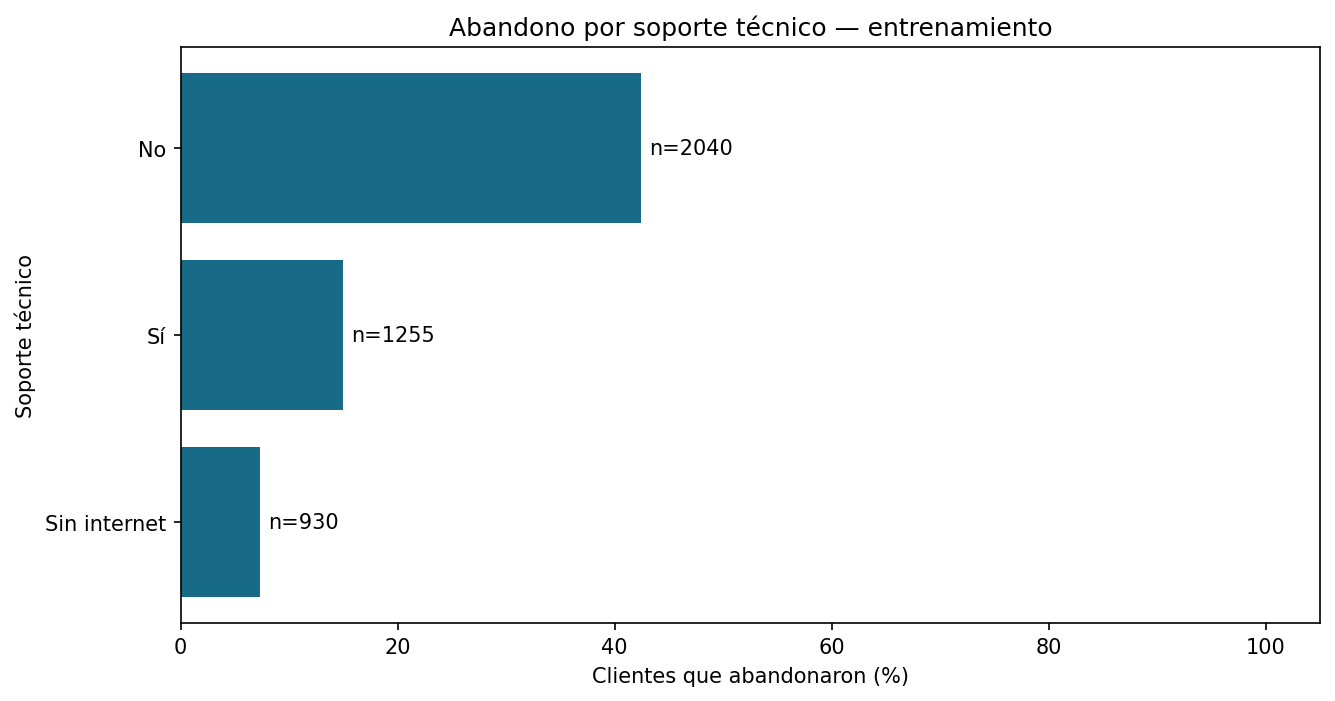

No: 42.4% (n=2040); No internet service: 7.3% (n=930). Es una asociación histórica, no una causa demostrada.

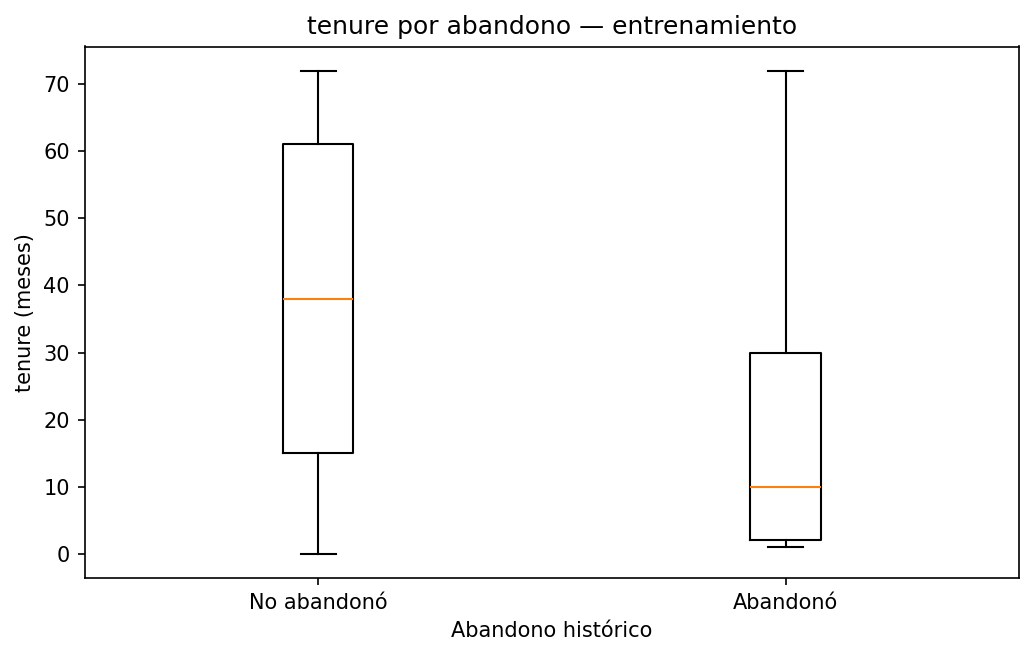

Mediana de tenure: No=38.00, Yes=10.00 meses. Los valores atípicos se muestran, no se eliminan.

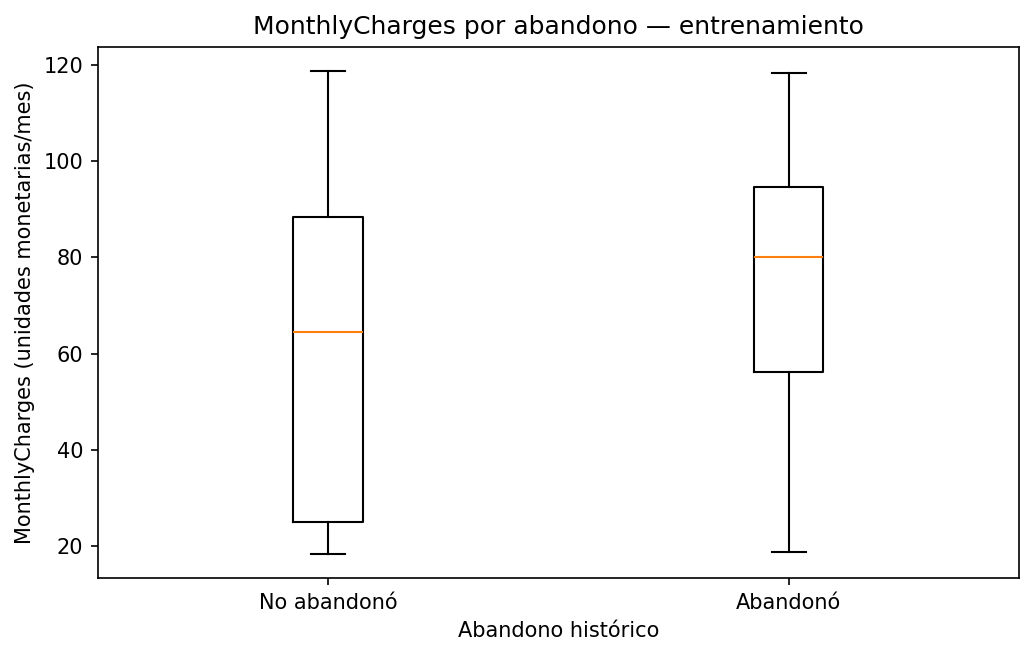

Mediana de MonthlyCharges: No=64.40, Yes=80.00 unidades monetarias/mes. Los valores atípicos se muestran, no se eliminan.

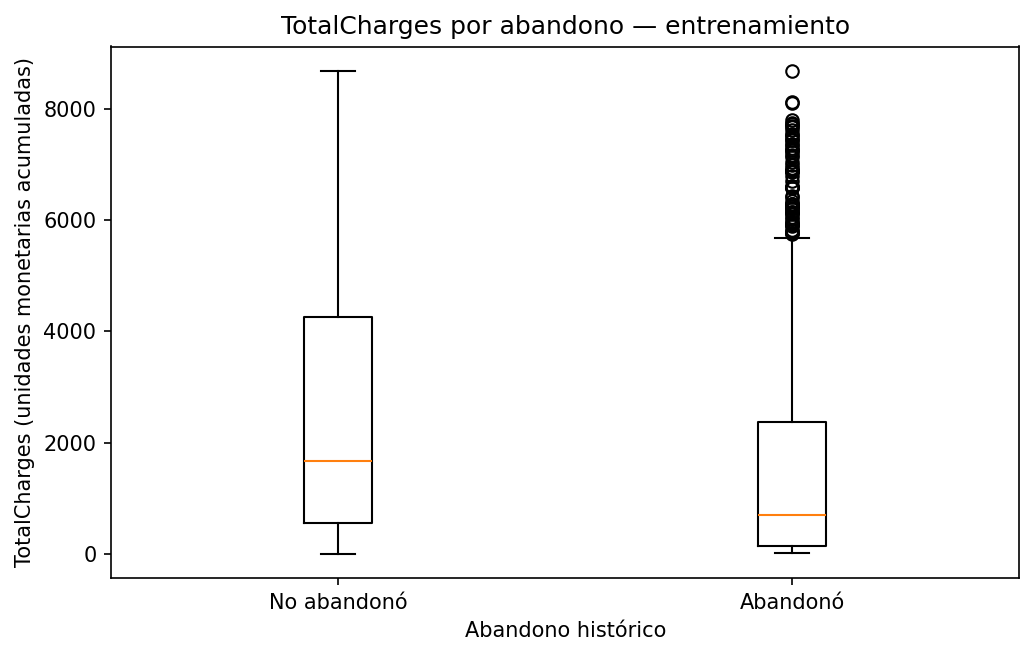

Mediana de TotalCharges: No=1672.10, Yes=692.10 unidades monetarias acumuladas. Los valores atípicos se muestran, no se eliminan.

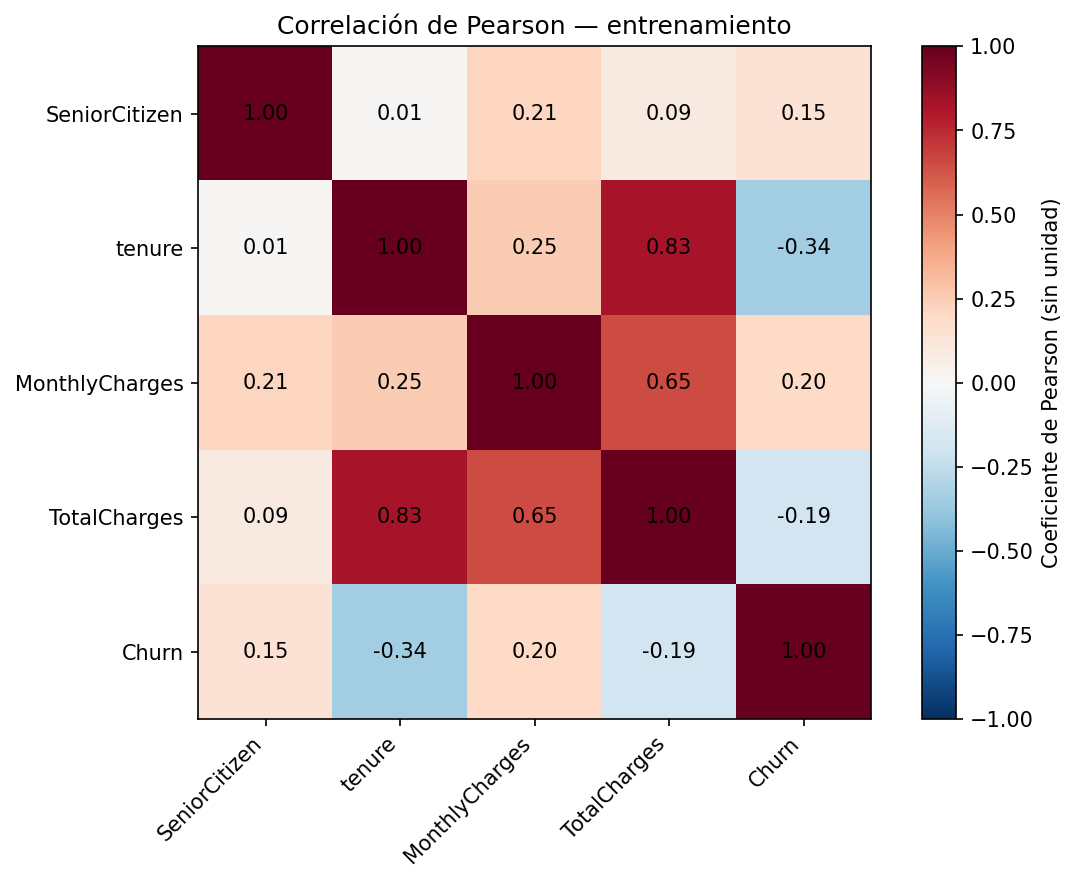

Las correlaciones son descriptivas y no prueban causalidad. Churn se codifica No=0, Yes=1; SeniorCitizen es un indicador binario.

CSV original intacto. Figuras: 9


In [5]:
report = generate_eda_report(RAW_DATA_PATH, manifest_path, DATA_REPORT_DIR)
for item in report["conclusions"]:
    display(Image(filename=str(DATA_REPORT_DIR / item["figure"])))
    display(Markdown(item["conclusion"]))
assert dataset_sha256(RAW_DATA_PATH) == original_hash
print("CSV original intacto. Figuras:", len(report["figures"]))

## Entrega y límites

Los JSON/CSV/PNG de `reports/data/` registran huella, calidad, estadísticas, tamaños de
segmento y conclusiones observadas. Los importes usan unidades monetarias: el CSV no
documenta una moneda. Las asociaciones no prueban causas.

El mismo CSV y manifiesto congelado se reutilizan en modelos y explicabilidad. Las
medianas, codificación y escalado se ajustan exclusivamente dentro del pipeline y de
sus folds. La comparación de modelos y métricas se presenta en el notebook 02.
Este notebook y su copia ejecutada forman parte de la entrega académica en GitHub.